![MOMENTUM · Hackatón de DRL · Evaluación](img/banner-test.jpg)

# **Código para la evaluación del agente**

Este cuaderno permite cargar un agente guardado con [train.ipynb](./train.ipynb) y evaluar su comportamiento en `highway-v0` durante **20 episodios**. Calcularemos la recompensa media y estadísticas de conducción y, finalmente, visualizaremos cómo actúa el agente durante un episodio completo.

Como siempre, comenzamos importando las librerías necesarias y definiendo funciones auxiliares:

In [ ]:
import gymnasium as gym
import highway_env

import numpy as np
from matplotlib import pyplot as plt
from IPython.display import clear_output
from stable_baselines3 import A2C, DQN, PPO

%matplotlib inline


def show_state(env):
    """
    Muestra el estado actual del entorno.
    """
    img = env.render()
    clear_output(wait=True)
    plt.imshow(img)
    plt.axis("off")
    plt.show()
    plt.close()

## **1. Entorno de evaluación**

### **1.1 Definición del entorno**

Creamos una instancia independiente del entorno utilizado durante el entrenamiento. Debemos mantener la misma configuración del entorno, incluidos sus espacios de observaciones y acciones.

In [ ]:
# Indica el entorno para el entrenamiento. Puedes cambiarlo por otro entorno de highway-env si lo deseas.
EVAL_ENV_NAME = 'highway-v0'

# Crear el entorno con la misma configuracion que en train.ipynb
eval_env = gym.make(EVAL_ENV_NAME, render_mode='rgb_array')

### **1.2 Definición y aplicación de wrappers**

Define los wrappers en la siguiente celda y llámalos en la función `aplicar_wrappers`. Recuerda que **debes aplicar los mismos wrappers, con los mismos parámetros y en el mismo orden que durante el entrenamiento** ya que, como vimos en [el tercer ejemplo](./ejemplos/03_wrappers.ipynb), estos wrappers pueden modificar las observaciones, acciones y recompensas. El archivo del agente no guarda automáticamente tus wrappers; si alguno utiliza estadísticas aprendidas de normalización, debes restaurarlas y fijarlas para evaluar.

Los wrappers deben conservar `info["speed"]` e `info["crashed"]`, ya que los usaremos para calcular las estadísticas.

Si no utilizaste wrappers, puedes dejar la celda tal y como está.

In [ ]:
# Define aqui los mismos wrappers utilizados en train.ipynb

# class wrapper_1(gym.ObservationWrapper):
# ...

# class wrapper_2(gym.ActionWrapper):
# ...

from wrapper import aplicar_wrappers
# Llama aqui a todos los wrappers, en el mismo orden y con los mismos parametros que durante el entrenamiento.
#def aplicar_wrappers(env):
    # env = wrapper_1(env)
    # env = wrapper_2(env)
#    return env


# Aplicar los wrappers al entorno antes de cargar el agente
eval_env = aplicar_wrappers(eval_env)

## **2. Carga del agente a evaluar**

Cargamos el archivo del agente que queramos evaluar: `agentes/<nombre_experimento>/best_model.zip`, guardado durante el estudio de Optuna.

**El algoritmo utilizado para cargar el agente debe coincidir con el utilizado para entrenar.** Para ello, no olvides ajustar el valor de la variable `ALGORITMO` antes de ejecutar la evaluación.

In [18]:
# Configuracion del modelo que vamos a evaluar
EXPERIMENT_NAME = "PPO-safetrack_wrapper"
ALGORITMO = PPO  # Algoritmo utilizado para entrenamiento

agent = ALGORITMO.load(f"agentes/{EXPERIMENT_NAME}/best_model.zip", env=eval_env)

## **3. Evaluación del agente**

### **3.1 Configuración de la evaluación**

Evaluamos durante **20 episodios**, utilizando una semilla distinta para cada uno. Estas semillas se reservan para el test y no deben utilizarse para seleccionar hiperparámetros durante el entrenamiento.

Usaremos `deterministic=True` en `predict`, como en [el segundo notebook de ejemplo](./ejemplos/02_agentes.ipynb), para evitar la exploración durante la evaluación.

In [19]:
# Variables fijas de evaluacion
EVAL_EPISODES = 20
TEST_SEED = 200
TEST_SEEDS = [TEST_SEED + i for i in range(EVAL_EPISODES)]

### **3.2 Ejecución de los episodios**

Utilizamos el bucle de interacción agente-entorno de los ejemplos en lugar de `evaluate_policy`, para recoger también la información adicional de cada paso:

- **Recompensa acumulada:** suma de las recompensas del episodio, sin descuento. Si aplicas un wrapper de recompensa, corresponde a la recompensa transformada.
- **Velocidad media:** media de `info["speed"]`, en m/s, después de cada acción. No la calculamos a partir de las observaciones, ya que pueden estar normalizadas o transformadas.
- **Colisión:** registramos si el vehículo del agente ha colisionado en algún momento del episodio.
- **Longitud del episodio:** número de pasos ejecutados hasta que `terminated` o `truncated` sea verdadero.

En `highway-v0` por defecto, una colisión termina el episodio. Por tanto, el número de episodios con colisión coincide con el número de accidentes del agente.

In [20]:
# Crear variables para almacenar las metricas
episode_rewards = []
episode_mean_speeds = []
episode_collisions = []
episode_lengths = []

# Bucle de evaluacion
for episode_seed in TEST_SEEDS:
    state, info = eval_env.reset(seed=episode_seed)
    terminated = truncated = False

    episode_reward = 0.0
    speeds = []
    collided = False
    steps = 0

    while not (terminated or truncated):
        action, _ = agent.predict(state, deterministic=True)
        state, reward, terminated, truncated, info = eval_env.step(action)

        episode_reward += float(reward)
        speeds.append(float(info["speed"]))
        collided = collided or bool(info["crashed"])
        steps += 1

    episode_rewards.append(episode_reward)
    episode_mean_speeds.append(float(np.mean(speeds)))
    episode_collisions.append(collided)
    episode_lengths.append(steps)

eval_env.close()

### **3.3 Resultados de la evaluación**

Una vez ha terminado la evaluación, mostramos la recompensa media y su desviación típica entre episodios. 

Para la velocidad, primero calculamos la media de cada episodio y después promediamos esas medias: **todos los episodios tienen el mismo peso**, aunque varíe su duración.

La tasa de colisión indica el porcentaje de episodios en los que el agente ha colisionado. Una recompensa alta debe interpretarse junto con estas estadísticas de conducción.

La siguiente información también se escribe en el archivo `agentes/<EXPERIMENT_NAME>/info_eval.txt`.

In [21]:
# Calcular metricas
mean_reward = np.mean(episode_rewards)
std_reward = np.std(episode_rewards)
mean_speed = np.mean(episode_mean_speeds)
std_speed = np.std(episode_mean_speeds)
collisions = int(np.sum(episode_collisions))
collision_rate = 100 * collisions / EVAL_EPISODES
mean_length = np.mean(episode_lengths)

# Mostrar resultados
print(f"Episodios evaluados: {EVAL_EPISODES}")
print(f"Recompensa media obtenida: {mean_reward:.2f} ± {std_reward:.2f}")
print(f"Velocidad media por episodio: {mean_speed:.2f} ± {std_speed:.2f} m/s")
print(f"Episodios con colision: {collisions} de {EVAL_EPISODES} ({collision_rate:.1f} %)")
print(f"Longitud media de los episodios: {mean_length:.1f} pasos")

# Escribir informacion util sobre la evaluacion en un archivo de texto
with open(f"agentes/{EXPERIMENT_NAME}/info_eval.txt", "w") as f:
    f.write(f"Informacion sobre la evaluacion del agente {EXPERIMENT_NAME}:")
    f.write(f"\n - Entorno de evaluacion: {EVAL_ENV_NAME}")
    f.write(f"\n - Episodios evaluados: {EVAL_EPISODES}")
    f.write(f"\n - Recompensa media obtenida: {mean_reward:.2f} ± {std_reward:.2f}")
    f.write(f"\n - Velocidad media por episodio: {mean_speed:.2f} ± {std_speed:.2f} m/s")
    f.write(f"\n - Episodios con colision: {collisions} de {EVAL_EPISODES} ({collision_rate:.1f} %)")
    f.write(f"\n - Longitud media de los episodios: {mean_length:.1f} pasos")

Episodios evaluados: 20
Recompensa media obtenida: 25.95 ± 6.42
Velocidad media por episodio: 20.35 ± 0.96 m/s
Episodios con colision: 2 de 20 (10.0 %)
Longitud media de los episodios: 37.0 pasos


## **4. Visualización de una episodio de ejemplo**

Por último, mostramos de forma gráfica el comportamiento del agente durante un episodio en el mismo entorno, aunque con una semilla diferente. Ten en cuenta que **este episodio es ilustrativo y no tiene por qué reflejar las estadísticas anteriores.** Puedes modificar el valor de `VISUAL_SEED` para visualizar otra simulación diferente.

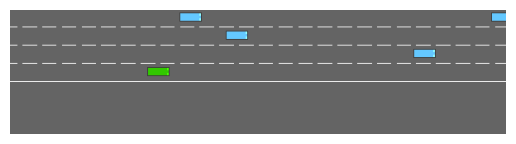

Recompensa del episodio mostrado: 29.11
¿Ha colisionado el agente?: No


In [23]:
VISUAL_SEED = TEST_SEED + EVAL_EPISODES + 1

try:
    state, info = eval_env.reset(seed=VISUAL_SEED)
    terminated = truncated = False
    visual_reward = 0.0
    visual_collision = False

    show_state(eval_env)

    while not (terminated or truncated):
        action, _ = agent.predict(state, deterministic=True)
        state, reward, terminated, truncated, info = eval_env.step(action)

        visual_reward += float(reward)
        visual_collision = visual_collision or bool(info["crashed"])
        show_state(eval_env)

    print(f"Recompensa del episodio mostrado: {visual_reward:.2f}")
    print(f"¿Ha colisionado el agente?: {'Sí' if visual_collision else 'No'}")
finally:
    eval_env.close()

***

## **5. Instrucciones para la entrega del agente**

Al final del hackatón, entrega **una carpeta con el nombre de tu equipo** que contenga:

- `best_model.zip`: tu mejor agente, copiado de `agentes/<EXPERIMENT_NAME>/`.
- `wrappers.py`, solo si usaste wrappers: las clases de tus wrappers y una función `aplicar_wrappers(env)` que los aplique con los mismos parámetros y en el mismo orden que en `train.ipynb`, y devuelva el entorno envuelto, como en el siguiente ejemplo:

```python
class MiWrapper(...):
# ...

class OtroWrapper(...):
# ...

def aplicar_wrappers(env):
    env = MiWrapper(env)
    # env = OtroWrapper(env)
    return env
```

Todos los agentes se evalúan con las condiciones de este notebook, pero **la clasificación usa la recompensa original de `highway-v0`**: un wrapper de recompensa no cambia tu puntuación. A igual recompensa, gana quien tenga menos colisiones. Encontrarás todos los detalles en el apartado *Cómo entregar tu agente* del README del repositorio.